# **Set up the environment**

## **Installations**

In [1]:
# Takes about 45 seconds
%%capture
!pip install --quiet langchain langchain-core langchain-azure-ai langchain-milvus langchain-community langgraph
!pip install colorama

## **Imports**

In [10]:
%%capture
# -------------------------- For data manipulation --------------------------- #
import pandas as pd

# ----------------------------- For RAG creation ----------------------------- #
from langchain_azure_ai.chat_models import AzureAIChatCompletionsModel
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage
from langchain_azure_ai.embeddings import AzureAIEmbeddingsModel
from langchain_milvus import Milvus
from langchain_core.prompts import PromptTemplate, ChatPromptTemplate
from langchain_core.tools import tool

# ----------------------------- For Advanced RAG ----------------------------- #
from langchain.embeddings import HuggingFaceEmbeddings
from langchain.retrievers.document_compressors import DocumentCompressorPipeline
from langchain.retrievers.document_compressors.embeddings_filter import EmbeddingsFilter
from langchain.retrievers.contextual_compression import ContextualCompressionRetriever
from langchain_community.document_transformers import EmbeddingsRedundantFilter
from langchain_text_splitters import CharacterTextSplitter
import operator

# -------------------------- For LangGraph creation -------------------------- #
from langchain_core.documents import Document
from typing_extensions import List, TypedDict, Annotated
from langgraph.graph import START, END, StateGraph, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition, create_react_agent
from langgraph.checkpoint.memory import MemorySaver

# ---------------------------- For pretty outputs ---------------------------- #
from IPython.display import display, Markdown, Image
from textwrap import fill
from colorama import Fore

# ---------------------------- For mounting drive ---------------------------- #
from google.colab import drive
drive.mount('/content/drive')

## **Set up the GenAI endpoint**

In [ ]:
API_ENDPOINT = ""
API_KEY = ""
api_version = ""
uri = ""
# removed for privacy

## **Set up the GenAI components**

In [12]:
# ----------------------------- Component 1: LLM ----------------------------- #

# Available models ["Phi-4", "gpt-4o", "DeepSeek-R1", "Mistral-Nemo"]
llm = AzureAIChatCompletionsModel(
    endpoint=API_ENDPOINT,
    credential=API_KEY,
    model_name="gpt-4o",
    )

# ----------------------- Component 2: Embedding model ----------------------- #

embeddings = AzureAIEmbeddingsModel(
    endpoint=API_ENDPOINT,
    credential=API_KEY,
    model_name="text-embedding-3-small",
    )

# ------------------------ Component 3: Vector store ------------------------- #

vector_store = Milvus(
    embedding_function=embeddings,
    connection_args={"uri": uri}
    )

# --------------------- Component 4: Document retriever ---------------------- #
retriever = vector_store.as_retriever(search_kwargs={"k": 5})

# ------------------Component 5: Smaller model for filtering ----------------- #
small_embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

<ipython-input-12-7bec45b6b5b6>:29: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-huggingface package and should be used instead. To use it run `pip install -U :class:`~langchain-huggingface` and import as `from :class:`~langchain_huggingface import HuggingFaceEmbeddings``.
  small_embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public mode

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (2 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

## **Test the availability of the GenAI endpoint for chat completion and text embedding and functionality of Milvus**

In [14]:
# ------------------------------- Chat Completion ------------------------------

# Create a model object
model = AzureAIChatCompletionsModel(
    endpoint=API_ENDPOINT,
    credential=API_KEY,
    model_name="Phi-4",     # model_name in ["Phi-4", "gpt-4o", "DeepSeek-R1", "Mistral-Nemo"]
)

# Create a list of messages
messages = [
    SystemMessage(content="Translate the following from English into French"),
    HumanMessage(content="Hi there, what are we going to cook today ?"),
]

# Give the model a query and print the response
response = model.invoke(messages)
print(response.content)   # something like "Bonjour, qu'est-ce que nous allons cuisiner aujourd'hui ?"

Bonjour, qu'allons-nous cuisiner aujourd'hui ?


In [15]:
# ------------------------------- Text Embedding -------------------------------

# Create embedding object
embeddings = AzureAIEmbeddingsModel(
    endpoint=API_ENDPOINT,
    credential=API_KEY,
    model_name="text-embedding-3-small",
)

assert embeddings.embed_documents(["hey this is a document, embed me !!!"])

In [16]:
# ----------------------------------- Milvus -----------------------------------

# Create a Milvis object
vector_store_loaded = Milvus(
    embeddings,
    connection_args={"uri": uri},
)

# TEST
assert vector_store_loaded.similarity_search('arbitrage video', k=1)

# **Naive RAG Implementation 1.0**

In [17]:
# --------------------------- Retrieval & Generation ------------------------- #

# Create State class
class State(TypedDict):
    question_eng: str
    question_fr: str
    context: List[Document]
    answer: str

# Create custom prompts for the translation and generation phases
translation_template = """
        Translate the following from English to French.
        Give ONLY the translation.
        NO additional text.

        English text: {text}
    """

generation_template = """
        Use the following pieces of context to answer the question at the end.
        The pieces of context and question are in French.
        Do NOT answer in French!
        ALWAYS give your answers in English!
        If you don't know the answer, just say that you don't know, don't try to make up an answer.
        If the context provided is not suited to asnwering the question, just say you can't answer the question.

        {context}

        Question: {question}

        Helpful Answer:
    """

translation_prompt = PromptTemplate.from_template(translation_template)
generation_prompt = PromptTemplate.from_template(generation_template)

def translate(state: State):
    messages = translation_prompt.invoke({"text": state["question_eng"]})
    response = llm.invoke(messages)
    return {"question_fr": response.content}

def retrieve(state: State):
    retrieved_docs = vector_store.similarity_search(state["question_fr"])
    return {"context": retrieved_docs}

def generate(state: State):
    docs_content = "\n\n".join(doc.page_content for doc in state["context"])
    messages = generation_prompt.invoke({"question": state["question_fr"], "context": docs_content})
    response = llm.invoke(messages)
    return {"answer": response.content}


graph_builder = StateGraph(State).add_sequence([translate, retrieve, generate])
graph_builder.add_edge(START, "translate")
graph = graph_builder.compile()

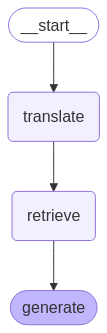

In [18]:
Image(graph.get_graph().draw_mermaid_png())

In [19]:
def get_answer(question: str, graph: StateGraph, show: bool=True):
    result = graph.invoke({"question_eng": question})

    if show:
        print('Answer:', '='*60, sep='\n')
        display(Markdown(result["answer"]))
        print()

        print(Fore.LIGHTBLACK_EX + 'Sources:', Fore.LIGHTBLACK_EX + '='*60, sep='\n')
        sources = '\n'.join([Fore.LIGHTBLACK_EX + f"{i}) {doc.metadata['url']}" for i, doc in enumerate(result['context'], start=1)])
        print(sources)

    return result

# question = "Summarize in bullet points the point of view on the usage of video assisted refereeing ? "
question = "Explain the concept of manifest destiny"

answer = get_answer(question=question, graph=graph)

Answer:


I can't answer the question based on the context provided because the concept of "destinée manifeste" (Manifest Destiny) is not mentioned or explained within the given text.


Sources:
1) https://www.cahiersdufootball.net/article/du-tirage-dans-la-consigne-2263?page=2
2) https://www.cahiersdufootball.net/article/du-tirage-dans-la-consigne-2263?page=3
3) https://www.cahiersdufootball.net/article/du-tirage-dans-la-consigne-2263
4) https://www.cahiersdufootball.net/article/fernandez-deja-sur-la-corde-raide-1294?page=3


# **Naive RAG Implementation 2.0**

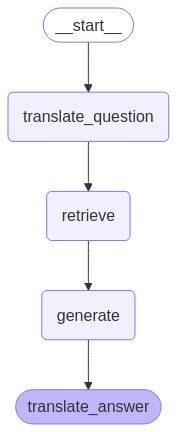

In [20]:
# --------------------------- Retrieval & Generation ------------------------- #

# Create State class
class State(TypedDict):
    question_eng: str
    question_fr: str
    context: List[Document]
    answer_eng: str
    answer_fr: str

# Create custom prompts for the translation and generation phases
translation_template = """
        Translate the following between English and French.
        If the text is in English, translate it to French.
        If the text is in French, translate it to English.
        Give ONLY the translation.
        NO additional text.

        Text: {text}
    """

generation_template = """
        Use the following pieces of context to answer the question at the end.
        The pieces of context and question are in French.
        Give your answer in French!
        If you don't know the answer, just say that you don't know, don't try to make up an answer.
        If the context provided is not suited to asnwering the question, just say you can't answer the question.

        {context}

        Question: {question}

        Helpful Answer:
    """

translation_prompt = PromptTemplate.from_template(translation_template)
generation_prompt = PromptTemplate.from_template(generation_template)

def translate_question(state: State):
    messages = translation_prompt.invoke({"text": state["question_eng"]})
    response = llm.invoke(messages)
    return {"question_fr": response.content}

def retrieve(state: State):
    retrieved_docs = vector_store.similarity_search(state["question_fr"])
    return {"context": retrieved_docs}

def generate(state: State):
    docs_content = "\n\n".join(doc.page_content for doc in state["context"])
    messages = generation_prompt.invoke({"question": state["question_fr"], "context": docs_content})
    response = llm.invoke(messages)
    return {"answer_fr": response.content}

def translate_answer(state: State):
    messages = translation_prompt.invoke({"text": state["answer_fr"]})
    response = llm.invoke(messages)
    return {"answer_eng": response.content}

graph_builder = StateGraph(State).add_sequence([translate_question, retrieve, generate, translate_answer])
graph_builder.add_edge(START, "translate_question")
graph = graph_builder.compile()

Image(graph.get_graph().draw_mermaid_png())

In [21]:
def get_answer(question: str, graph: StateGraph, show: bool=True):
    result = graph.invoke({"question_eng": question})

    if show:
        print('Answer:', '='*60, sep='\n')
        display(Markdown(result["answer_eng"]))
        print()

        print(Fore.LIGHTBLACK_EX + 'Sources:', Fore.LIGHTBLACK_EX + '='*60, sep='\n')
        sources = '\n'.join([Fore.LIGHTBLACK_EX + f"{i}) {doc.metadata['url']}" for i, doc in enumerate(result['context'], start=1)])
        print(sources)

    return result

# question = "Summarize in bullet points the point of view on the usage of video assisted refereeing ? "
question = "Explain the concept of manifest destiny"

answer = get_answer(question=question, graph=graph)

Answer:


I cannot answer the question about the concept of "manifest destiny" with the provided context, as it does not address this topic.


Sources:
1) https://www.cahiersdufootball.net/article/du-tirage-dans-la-consigne-2263?page=2
2) https://www.cahiersdufootball.net/article/du-tirage-dans-la-consigne-2263?page=3
3) https://www.cahiersdufootball.net/article/du-tirage-dans-la-consigne-2263
4) https://www.cahiersdufootball.net/article/fernandez-deja-sur-la-corde-raide-1294?page=3


# **Advanced RAG Implementation: Rewrite-Retrieve-Read 1.0**

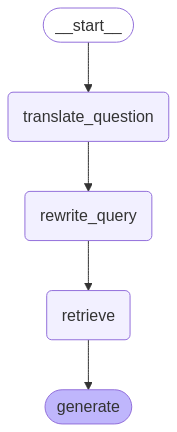

In [22]:
# --------------------------- Retrieval & Generation ------------------------- #

# Create State class
class State(TypedDict):
    question: str
    question_fr: str
    query: str
    context: List[Document]
    answer: str

# Create custom prompts for the query rewriting, translation and generation phases
translation_template = """
        Translate the following between English and French.
        If the text is in English, translate it to French.
        If the text is in French, translate it to English.
        Give ONLY the translation.
        NO additional text.

        Text: {text}
    """

rewriting_template = """
    Provide a better search query for a large language model to answer the given question.
    Write your query in French.
    Return only the rewritten query, not any decorative text.

    Question: {question}

    Answer:
    """

generation_template = """
        Use the following pieces of context to answer the question at the end.
        The pieces of context and question are in French.
        Do NOT answer in French!
        ALWAYS give your answers in English!
        If you don't know the answer, just say that you don't know, don't try to make up an answer.
        If the context provided is not suited to asnwering the question, just say you can't answer the question.

        {context}

        Question: {question}

        Helpful Answer:
    """

translation_prompt = PromptTemplate.from_template(translation_template)
rewriting_prompt = PromptTemplate.from_template(rewriting_template)
generation_prompt = PromptTemplate.from_template(generation_template)

def translate_question(state: State):
    messages = translation_prompt.invoke({"text": state["question"]})
    response = llm.invoke(messages)
    return {"question_fr": response.content}

def rewrite_query(state: State):
    messages = rewriting_prompt.invoke({"question": state["question_fr"]})
    response = llm.invoke(messages)
    return {"query" : response.content}

def retrieve(state: State):
    retrieved_docs = vector_store.similarity_search(state["query"])
    return {"context": retrieved_docs}

def generate(state: State):
    docs_content = "\n\n".join(doc.page_content for doc in state["context"])
    messages = generation_prompt.invoke({"question": state["query"], "context": docs_content})
    response = llm.invoke(messages)
    return {"answer": response.content}

nodes = [translate_question, rewrite_query, retrieve, generate]
graph_builder = StateGraph(State).add_sequence(nodes=nodes)
graph_builder.add_edge(START, "translate_question")
graph = graph_builder.compile()

Image(graph.get_graph().draw_mermaid_png())

In [23]:
def get_answer(question: str, graph: StateGraph, show: bool=True):
    result = graph.invoke({"question": question})

    if show:
        print('Answer:', '='*60, sep='\n')
        display(Markdown(result["answer"]))
        print()

        print(Fore.LIGHTBLACK_EX + 'Sources:', Fore.LIGHTBLACK_EX + '='*60, sep='\n')
        sources = '\n'.join([Fore.LIGHTBLACK_EX + f"{i}) {doc.metadata['url']}" for i, doc in enumerate(result['context'], start=1)])
        print(sources)

    return result

question = "Summarize in bullet points the point of view on the usage of video assisted refereeing ? "
# question = "Explain the concept of manifest destiny"

answer = get_answer(question=question, graph=graph)

Answer:


The main arguments for and against the use of video refereeing in sports based on the context provided are:

**For:**
- Improving the quality of refereeing by utilizing all available tools and technology.
- Ensuring fair and accurate decisions, particularly in high-stakes competitions.

**Against:**
- Issues of universality, as not all organizations or regions may afford the necessary equipment for video refereeing, creating inequality.
- Severe practical difficulties such as deciding when, how, how often, and for what specific situations video refereeing should be applied during a match.
- The risk of rushing into a system that could bring significant drawbacks or dangers to the sport, potentially disrupting its essence.

The debate calls for careful consideration before adopting video refereeing on a large scale.


Sources:
1) https://www.cahiersdufootball.net/article/video-arbitrage-ineluctable-et-inutile-6300?page=2
2) https://www.cahiersdufootball.net/article/video-arbitrage-ineluctable-et-inutile-6300
3) https://www.cahiersdufootball.net/article/video-arbitrage-ineluctable-et-inutile-6300?page=1
4) https://www.cahiersdufootball.net/article/manifeste-contre-larbitrage-video-7001?page=4


In [24]:
# Print context
for doc in answer['context']:
    print(doc.page_content)

Elles portent sur l’universalité de l’arbitrage (tout le monde ne pourra pas s’offrir le matériel nécessaire) et les énormes difficultés pratiques que posera le recours à la vidéo en plein match (quand, comment, combien de fois, pourquoi, etc.).
Elles portent sur l’universalité de l’arbitrage (tout le monde ne pourra pas s’offrir le matériel nécessaire) et les énormes difficultés pratiques que posera le recours à la vidéo en plein match (quand, comment, combien de fois, pourquoi, etc.).
Elles portent sur l’universalité de l’arbitrage (tout le monde ne pourra pas s’offrir le matériel nécessaire) et les énormes difficultés pratiques que posera le recours à la vidéo en plein match (quand, comment, combien de fois, pourquoi, etc.).
L'alternative est plutôt la suivante : met-on en œuvre tous les moyens pour améliorer la qualité de l'arbitrage ou se précipite-t-on dans une « solution » qui présente de graves dangers pour le football ? Le débat peut-il commencer ? Avec la mise en œuvre de l’a

# **Advanced RAG Implementation: Rewrite-Retrieve-Read 2.0**

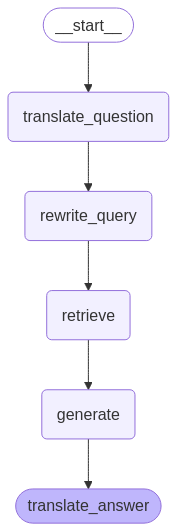

In [25]:
# --------------------------- Retrieval & Generation ------------------------- #

# Create State class
class State(TypedDict):
    question: str
    question_fr: str
    query: str
    context: List[Document]
    answer_fr: str
    answer_eng: str

# Create custom prompts for the query rewriting, translation and generation phases
translation_template = """
        Translate the following between English and French.
        If the text is in English, translate it to French.
        If the text is in French, translate it to English.
        Give ONLY the translation.
        NO additional text.

        Text: {text}
    """

rewriting_template = """
    Provide a better search query for a large language model to answer the given question.
    Write your query in French.
    Return only the rewritten query, not any decorative text.

    Question: {question}

    Answer:
    """

generation_template = """
        Use the following pieces of context to answer the question at the end.
        The pieces of context and question are in French.
        Give your answer in French!
        If you don't know the answer, just say that you don't know, don't try to make up an answer.
        If the context provided is not suited to asnwering the question, just say you can't answer the question.

        {context}

        Question: {question}

        Helpful Answer:
    """

translation_prompt = PromptTemplate.from_template(translation_template)
rewriting_prompt = PromptTemplate.from_template(rewriting_template)
generation_prompt = PromptTemplate.from_template(generation_template)

def translate_question(state: State):
    messages = translation_prompt.invoke({"text": state["question"]})
    response = llm.invoke(messages)
    return {"question_fr": response.content}

def rewrite_query(state: State):
    messages = rewriting_prompt.invoke({"question": state["question_fr"]})
    response = llm.invoke(messages)
    return {"query" : response.content}

def retrieve(state: State):
    retrieved_docs = vector_store.similarity_search(state["query"])
    return {"context": retrieved_docs}

def generate(state: State):
    docs_content = "\n\n".join(doc.page_content for doc in state["context"])
    messages = generation_prompt.invoke({"question": state["query"], "context": docs_content})
    response = llm.invoke(messages)
    return {"answer_fr": response.content}

def translate_answer(state: State):
    messages = translation_prompt.invoke({"text": state["answer_fr"]})
    response = llm.invoke(messages)
    return {"answer_eng": response.content}

nodes = [translate_question, rewrite_query, retrieve, generate, translate_answer]
graph_builder = StateGraph(State).add_sequence(nodes=nodes)
graph_builder.add_edge(START, "translate_question")
graph = graph_builder.compile()

Image(graph.get_graph().draw_mermaid_png())

In [26]:
def get_answer(question: str, graph: StateGraph, show: bool=True):
    result = graph.invoke({"question": question})

    if show:
        print('Answer:', '='*60, sep='\n')
        display(Markdown(result["answer_eng"]))
        print()

        print(Fore.LIGHTBLACK_EX + 'Sources:', Fore.LIGHTBLACK_EX + '='*60, sep='\n')
        sources = '\n'.join([Fore.LIGHTBLACK_EX + f"{i}) {doc.metadata['url']}" for i, doc in enumerate(result['context'], start=1)])
        print(sources)

    return result

# question = "Summarize in bullet points the point of view on the usage of video assisted refereeing ? "
question = "Explain the concept of manifest destiny"

answer = get_answer(question=question, graph=graph)

Answer:


I cannot answer the question about the concept of manifest destiny and its historical and political implications, because the provided context does not address this topic.


Sources:
1) https://www.cahiersdufootball.net/article/le-retour-de-superdupont-5578
2) https://www.cahiersdufootball.net/article/10-bonnes-raisons-davoir-perdu-contre-la-hollande-165
3) https://www.cahiersdufootball.net/article/10-bonnes-raisons-davoir-perdu-contre-la-hollande-165?page=1
4) https://www.cahiersdufootball.net/article/langoisse-du-lyceen-au-moment-du-rattrapage-5936


In [27]:
# messages = rewriting_prompt.invoke({"question": question})
# response = llm.invoke(messages)
# response.content

# **Advanced RAG Implementation: Adding Document Compression and Filtering**

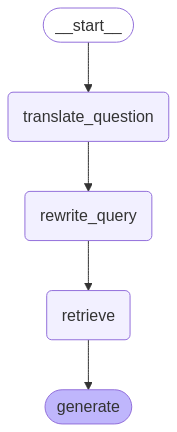

In [28]:
# --------------------------- Retrieval & Generation ------------------------- #

# Create State class
class State(TypedDict):
    question: str
    question_fr: str
    query: str
    context: List[Document]
    answer: str

# Create custom prompts for the query rewriting, translation and generation phases
translation_template = """
        Translate the following between English and French.
        If the text is in English, translate it to French.
        If the text is in French, translate it to English.
        Give ONLY the translation.
        NO additional text.

        Text: {text}
    """

rewriting_template = """
    Provide a better search query for a large language model to answer the given question.
    Write your query in French.
    Return only the rewritten query, not any decorative text.

    Question: {question}

    Answer:
    """

generation_template = """
        Use the following pieces of context to answer the question at the end.
        The pieces of context and question are in French.
        Do NOT answer in French!
        ALWAYS give your answers in English!
        If you don't know the answer, just say that you don't know, don't try to make up an answer.
        If the context provided is not suited to asnwering the question, just say you can't answer the question.

        {context}

        Question: {question}

        Helpful Answer:
    """

translation_prompt = PromptTemplate.from_template(translation_template)
rewriting_prompt = PromptTemplate.from_template(rewriting_template)
generation_prompt = PromptTemplate.from_template(generation_template)

def translate_question(state: State):
    messages = translation_prompt.invoke({"text": state["question"]})
    response = llm.invoke(messages)
    return {"question_fr": response.content}

def rewrite_query(state: State):
    messages = rewriting_prompt.invoke({"question": state["question_fr"]})
    response = llm.invoke(messages)
    return {"query" : response.content}

def retrieve(state: State):
    splitter = CharacterTextSplitter(chunk_size=300,
                                     chunk_overlap=0,
                                     separator=". ")

    redundant_filter = EmbeddingsRedundantFilter(embeddings=embeddings)

    relevant_filter = EmbeddingsFilter(embeddings=embeddings,
                                       similarity_threshold=0.65)

    pipeline_compressor = DocumentCompressorPipeline(
        transformers=[splitter, redundant_filter, relevant_filter])

    compression_retriever = ContextualCompressionRetriever(
                                base_compressor=pipeline_compressor,
                                base_retriever=retriever)

    compressed_docs = compression_retriever.invoke(state["query"])
    return {"context": compressed_docs}

def generate(state: State):
    docs_content = "\n\n".join(doc.page_content for doc in state["context"])
    messages = generation_prompt.invoke({"question": state["query"], "context": docs_content})
    response = llm.invoke(messages)
    return {"answer": response.content}

nodes = [translate_question, rewrite_query, retrieve, generate]
graph_builder = StateGraph(State).add_sequence(nodes=nodes)
graph_builder.add_edge(START, "translate_question")
graph = graph_builder.compile()

Image(graph.get_graph().draw_mermaid_png())

In [29]:
def get_answer(question: str, graph: StateGraph, show: bool=True):
    result = graph.invoke({"question": question})

    if show:
        print('Answer:', '='*60, sep='\n')
        display(Markdown(result["answer"]))
        print()

        print(Fore.LIGHTBLACK_EX + 'Sources:', Fore.LIGHTBLACK_EX + '='*60, sep='\n')
        sources = '\n'.join([Fore.LIGHTBLACK_EX + f"{i}) {doc.metadata['url']}" for i, doc in enumerate(result['context'], start=1)])
        print(sources)

    return result

question = "Summarize in bullet points the point of view on the usage of video assisted refereeing ? "
# question = "Explain the concept of manifest destiny"

answer = get_answer(question=question, graph=graph)

Answer:


I can't answer the question because the context does not provide explicit arguments for or against the use of video-assisted refereeing in football. It only mentions the need to improve refereeing quality and raises concerns about potential dangers of hastily implementing a solution like video assistance, without specifying what those dangers or benefits are.


Sources:
1) https://www.cahiersdufootball.net/article/manifeste-contre-l-arbitrage-video-7001?page=3


In [30]:
for doc in answer['context']:
    print(doc.page_content)

chunks = [doc.page_content for doc in answer['context']]

L'alternative est plutôt la suivante : met-on en œuvre tous les moyens pour améliorer la qualité de l'arbitrage ou se précipite-t-on dans une « solution » qui présente de graves dangers pour le football ? Le débat peut-il commencer ? Avec la mise en œuvre de l’arbitrage vidéo, à grande échelle, dans des compétitions majeures, le débat ne devrait plus être éludé.


# **Advanced RAG Implementation: Incorporating Chat History with Chains**

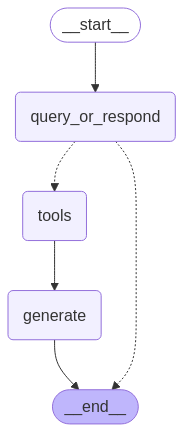

In [31]:
# --------------------------- Retrieval & Generation ------------------------- #

class State(MessagesState):
    context: List[Document]

# Create custom prompts for the query rewriting, translation and generation phases
translation_template = """
        Translate the following between English and French.
        If the text is in English, translate it to French.
        If the text is in French, translate it to English.
        Give ONLY the translation.
        NO additional text.

        Text: {text}
    """

translation_prompt = PromptTemplate.from_template(translation_template)

def translate_query(txt: str):
    messages = translation_prompt.invoke({"text": txt})
    response = llm.invoke(messages)
    return response.content

# Step 0: Create the retrieval tool
@tool(response_format="content_and_artifact")
def retrieve(query: str):
    """Retrieve information related to a query."""
    query_fr = translate_query(txt=query)
    retrieved_docs = vector_store.similarity_search(query_fr)
    serialized = "\n\n".join(
        (f"Source: {doc.metadata}\n" f"Content: {doc.page_content}")
        for doc in retrieved_docs
    )
    return serialized, retrieved_docs

# Step 1: Generate an AIMessage that may include a tool-call to be sent.
def query_or_respond(state: MessagesState):
    """Generate tool call for retrieval or respond."""
    llm_with_tools = llm.bind_tools([retrieve])
    response = llm_with_tools.invoke(state["messages"])

    # MessagesState appends messages to state instead of overwriting
    return {"messages": [response]}


# Step 2: Execute the retrieval.
tools = ToolNode([retrieve])


# Step 3: Generate a response using the retrieved content.
def generate(state: MessagesState):
    """Generate answer."""
    # Get generated ToolMessages
    recent_tool_messages = []
    for message in reversed(state["messages"]):
        if message.type == "tool":
            recent_tool_messages.append(message)
        else:
            break
    tool_messages = recent_tool_messages[::-1]

    # Format into prompt
    docs_content = "\n\n".join(doc.content for doc in tool_messages)
    system_message_content = (
        """
        Role:
        You are an advanced AI assistant that helps users answer questions in
        English, even when the source documents are in French.

        Answer Generation Strategy:
        First Attempt: Answer in English directly using the French context.
        If clarity is insufficient: Translate the French context into English
        first, then generate the final answer.

        Guidelines for Answering:
        Ensure responses are accurate, fluent, and natural in English.
        If needed, clarify ambiguous terms that may lose meaning in translation.
        Retain important names, technical terms, and quotes in their original
        form when appropriate.
        If a translation is used, ensure it maintains faithfulness to the
        original meaning while being easy to understand.

        Fallback Strategy:
        If you don't know the answer, say that you don't know. Don't try to make
        up answers or force an answer from the retrieved context. If the context
        is not useful for answering the question just say that. \n\n
        """

        f"{docs_content}"
    )
    conversation_messages = [
        message
        for message in state["messages"]
        if message.type in ("human", "system")
        or (message.type == "ai" and not message.tool_calls)
    ]
    prompt = [SystemMessage(system_message_content)] + conversation_messages

    # Run
    response = llm.invoke(prompt)
    context = []
    for tool_message in tool_messages:
        context.extend(tool_message.artifact)
    return {"messages": [response], "context": context}


def build_graph():
    graph_builder = StateGraph(State)
    graph_builder.add_node(query_or_respond)
    graph_builder.add_node(tools)
    graph_builder.add_node(generate)

    graph_builder.set_entry_point("query_or_respond")
    graph_builder.add_conditional_edges(
        "query_or_respond",
        tools_condition,
        {END: END, "tools": "tools"},
    )
    graph_builder.add_edge("tools", "generate")
    graph_builder.add_edge("generate", END)

    memory = MemorySaver()
    graph = graph_builder.compile(checkpointer=memory)

    return graph

graph = build_graph()

# Specify an ID for the thread
config = {"configurable": {"thread_id": "abc123"}}

Image(graph.get_graph().draw_mermaid_png())

In [32]:
# input_message = "Summarize in bullet points the point of view on the usage of video assisted refereeing?"

# for step in graph.stream(
#     {"messages": [{"role": "user", "content": input_message}]},
#     stream_mode="values", config=config
# ):
#     step["messages"][-1].pretty_print()

In [33]:
def chat(config: dict, show_sources: bool=False) -> None:
    graph = build_graph()

    keep_chatting = True
    # cxt = 0
    while keep_chatting:
        input_message = input()

        response = graph.invoke(input={"messages": [{"role": "user", "content": input_message}]},
                        stream_mode="values",
                        config=config)

        display(Markdown(response['messages'][-1].content))
        print()

        if 'thank' in input_message.lower().split() or 'thanks' in input_message.lower().split():
            break

        n_messages = len(response['messages'])
        tool_messages = [msg for msg in response['messages'][n_messages:] if msg.type == 'tool']

        if show_sources:
            print(Fore.LIGHTBLACK_EX + "Sources:")
            print(Fore.LIGHTBLACK_EX + "="*90)

        if show_sources and 'context' not in response.keys():
            print(Fore.LIGHTBLACK_EX + "No sources were used to give this answer.")
            print(Fore.WHITE + '')

        elif show_sources and 'context' in response.keys():
            for i, msg in enumerate(response['context'], start=1):
                print(Fore.LIGHTBLACK_EX + f"{i}) {msg.metadata['url']}")
            print(Fore.WHITE + '')

    return None

In [34]:
chat(config=config, show_sources=True)

how did neymar do at paris?


From the provided context, Neymar's impact at Paris Saint-Germain (PSG) was notable for both his playing ability and the strategic significance of his transfer.

1. **On-field Contribution**: Neymar displayed exceptional talent, vision, and intensity. After a remarkable victory against Lille (7-1), PSG's coach emphasized Neymar's key role, highlighting that he provided the team with "volume, balance, and intensity," qualities often missing in major European matches.

2. **Career Strategy**: Neymar's move to PSG was a strategic decision to elevate his career. He sought a "more advantageous position" at PSG compared to his status at Barcelona, where he was seen more as a supporting player to stars like Lionel Messi. At PSG, Neymar aimed to become the central figure around which the team revolved.

3. **Ambivalence of Status**: Neymar's presence at PSG represents not only his importance on the field but also the complexity and risks of building a team around one star player. This situation is sometimes referred to as “la neymarisation” of PSG, indicating how the club has been shaped around him.

In summary, Neymar brought skill and dynamism to PSG while also reshaping the club’s identity with his star power, but his tenure carries an inherent risk due to the dependency on him as a focal player.


Sources:
1) https://www.cahiersdufootball.net/article/neymar-comme-un-junior-7584
2) https://www.cahiersdufootball.net/article/la-neymarisation-du-psg-et-ses-risques-6772
3) https://www.cahiersdufootball.net/article/la-neymarisation-du-psg-et-ses-risques-6772?page=1
4) https://www.cahiersdufootball.net/article/boksic-a-en-perdre-alen-7372?page=1

thanks for explaining. How would you say his career in paris compared to his career in madrid?


Neymar has never played for Real Madrid. He began his European football career at Barcelona before moving to Paris Saint-Germain (PSG). Therefore, a comparison between his career at PSG and a hypothetical career at Madrid is not applicable. 

If you're referring to comparing his career at PSG with his time at Barcelona instead, I’d be happy to elaborate further! Let me know.

# **Advanced RAG Implementation: Incorporating Chat History with Chains w/ Document Compression**

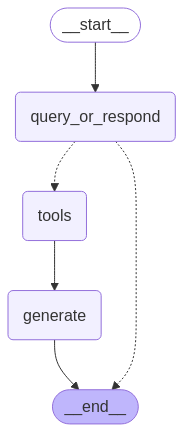

In [35]:
# --------------------------- Retrieval & Generation ------------------------- #

class State(MessagesState):
    context: List[Document]

# Create custom prompts for the query rewriting, translation and generation phases
translation_template = """
        Translate the following between English and French.
        If the text is in English, translate it to French.
        If the text is in French, translate it to English.
        Give ONLY the translation.
        NO additional text.

        Text: {text}
    """

translation_prompt = PromptTemplate.from_template(translation_template)

def translate_query(txt: str):
    messages = translation_prompt.invoke({"text": txt})
    response = llm.invoke(messages)
    return response.content

# Step 0: Create the retrieval tool
@tool(response_format="content_and_artifact")
def retrieve(query: str):
    """Retrieve information related to a query."""
    query_fr = translate_query(txt=query)

    splitter = CharacterTextSplitter(chunk_size=300,
                                     chunk_overlap=0,
                                     separator=". ")

    redundant_filter = EmbeddingsRedundantFilter(embeddings=embeddings)

    relevant_filter = EmbeddingsFilter(embeddings=embeddings,
                                       similarity_threshold=0.65)

    pipeline_compressor = DocumentCompressorPipeline(
        transformers=[splitter, redundant_filter, relevant_filter])

    compression_retriever = ContextualCompressionRetriever(
                                base_compressor=pipeline_compressor,
                                base_retriever=retriever)

    compressed_docs = compression_retriever.invoke(query_fr)

    serialized = "\n\n".join(
        (f"Source: {doc.metadata}\n" f"Content: {doc.page_content}")
        for doc in compressed_docs
    )
    return serialized, compressed_docs

# Step 1: Generate an AIMessage that may include a tool-call to be sent.
def query_or_respond(state: MessagesState):
    """Generate tool call for retrieval or respond."""
    llm_with_tools = llm.bind_tools([retrieve])
    response = llm_with_tools.invoke(state["messages"])

    # MessagesState appends messages to state instead of overwriting
    return {"messages": [response]}


# Step 2: Execute the retrieval.
tools = ToolNode([retrieve])


# Step 3: Generate a response using the retrieved content.
def generate(state: MessagesState):
    """Generate answer."""
    # Get generated ToolMessages
    recent_tool_messages = []
    for message in reversed(state["messages"]):
        if message.type == "tool":
            recent_tool_messages.append(message)
        else:
            break
    tool_messages = recent_tool_messages[::-1]

    # Format into prompt
    docs_content = "\n\n".join(doc.content for doc in tool_messages)
    system_message_content = (
        """
        Role:
        You are an advanced AI assistant that helps users answer questions in
        English, even when the source documents are in French.

        Answer Generation Strategy:
        First Attempt: Answer in English directly using the French context.
        If clarity is insufficient: Translate the French context into English
        first, then generate the final answer.

        Guidelines for Answering:
        Ensure responses are accurate, fluent, and natural in English.
        If needed, clarify ambiguous terms that may lose meaning in translation.
        Retain important names, technical terms, and quotes in their original
        form when appropriate.
        If a translation is used, ensure it maintains faithfulness to the
        original meaning while being easy to understand.

        Fallback Strategy:
        If you don't know the answer, say that you don't know. Don't try to make
        up answers or force an answer from the retrieved context. If the context
        is not useful for answering the question just say that. \n\n
        """

        f"{docs_content}"
    )
    conversation_messages = [
        message
        for message in state["messages"]
        if message.type in ("human", "system")
        or (message.type == "ai" and not message.tool_calls)
    ]
    prompt = [SystemMessage(system_message_content)] + conversation_messages

    # Run
    response = llm.invoke(prompt)
    context = []
    for tool_message in tool_messages:
        context.extend(tool_message.artifact)
    return {"messages": [response], "context": context}


def build_graph():
    graph_builder = StateGraph(State)
    graph_builder.add_node(query_or_respond)
    graph_builder.add_node(tools)
    graph_builder.add_node(generate)

    graph_builder.set_entry_point("query_or_respond")
    graph_builder.add_conditional_edges(
        "query_or_respond",
        tools_condition,
        {END: END, "tools": "tools"},
    )
    graph_builder.add_edge("tools", "generate")
    graph_builder.add_edge("generate", END)

    memory = MemorySaver()
    graph = graph_builder.compile(checkpointer=memory)

    return graph

graph = build_graph()

# Specify an ID for the thread
config = {"configurable": {"thread_id": "abc123"}}

Image(graph.get_graph().draw_mermaid_png())

In [36]:
input_message = "Summarize in bullet points the point of view on the usage of video assisted refereeing?"

for step in graph.stream(
    {"messages": [{"role": "user", "content": input_message}]},
    stream_mode="values", config=config
):
    step["messages"][-1].pretty_print()

================================ Human Message =================================

Summarize in bullet points the point of view on the usage of video assisted refereeing?
================================== Ai Message ==================================
Tool Calls:
  retrieve (call_ZXH8veM0ruzlw5E5keDXchZN)
 Call ID: call_ZXH8veM0ruzlw5E5keDXchZN
  Args:
    query: point of view on the usage of video assisted refereeing
================================= Tool Message =================================
Name: retrieve

Source: {'article_id': '822c3b9336402e55bbc91ee28ed0c660a8e39db5', 'pk': 456235803323047549, 'title': "L'arbitrage vidéo, une justice de classe ? - Les Cahiers du football || magazine de foot et d'eau fraîche", 'url': 'https://www.cahiersdufootball.net/article/larbitrage-video-une-justice-de-classe-6615?page=1'}
Content: L'arbitrage assisté par la vidéo, qui est l'aboutissement à la fois de ce processus et d'une convergence d'intérêts, annonce une justice dont il faut se demand

In [37]:
def chat(config: dict, show_sources: bool=False) -> None:
    graph = build_graph()

    keep_chatting = True
    # cxt = 0
    while keep_chatting:
        input_message = input()

        response = graph.invoke(input={"messages": [{"role": "user", "content": input_message}]},
                        stream_mode="values",
                        config=config)

        display(Markdown(response['messages'][-1].content))
        print()

        if 'thank' in input_message.lower().split() or 'thanks' in input_message.lower().split():
            break

        n_messages = len(response['messages'])
        tool_messages = [msg for msg in response['messages'][n_messages:] if msg.type == 'tool']

        if show_sources:
            print(Fore.LIGHTBLACK_EX + "Sources:")
            print(Fore.LIGHTBLACK_EX + "="*90)

        if show_sources and 'context' not in response.keys():
            print(Fore.LIGHTBLACK_EX + "No sources were used to give this answer.")
            print(Fore.WHITE + '')

        elif show_sources and 'context' in response.keys():
            for i, msg in enumerate(response['context'], start=1):
                print(Fore.LIGHTBLACK_EX + f"{i}) {msg.metadata['url']}")
            print(Fore.WHITE + '')

    return None

In [ ]:
chat(config=config, show_sources=True)

Neymar's time at Paris Saint-Germain (PSG) has been marked by both remarkable individual performances and significant challenges.

**Positive Highlights:**
1. **Stats and Influence:** Neymar has consistently showcased his extraordinary attacking talent during his stay at PSG, contributing with goals, assists, and dazzling displays. As one of the world's most skilled players, he has been a core figure in the team's attack.
2. **Major Achievements:** Neymar helped PSG dominate French domestic competitions, including Ligue 1 titles, Coupe de France, and Coupe de la Ligue wins. He was also instrumental in their 2019-2020 UEFA Champions League campaign, where PSG reached the final for the first time in the club's history (although they lost to Bayern Munich).
3. **Star Performances:** His technical ability and flair have often stood out, especially during key matches in both domestic and European tournaments.

**Challenges:**
1. **Injuries:** Neymar's time in Paris was frequently interrupted by injuries. These kept him out during critical parts of seasons, particularly during Champions League knockout stages.
2. **Scrutiny and Controversies:** Neymar faced criticism for perceived moments of inconsistency, disciplinary issues, and off-pitch controversies. His transfer cost and salary also placed immense expectations and pressure on him.
3. **Team Dynamics:** While Neymar formed strong partnerships with stars like Kylian Mbappé and Lionel Messi (later during Messi’s arrival), PSG often fell short of securing the Champions League title, which was a major goal when Neymar was signed for a world-record €222 million from Barcelona.

Overall, Neymar left his mark on PSG with moments of brilliance but his tenure could be seen by some as a mixed bag, given the high expectations surrounding his signing. While he brought entertainment and success domestically, the elusive Champions League triumph remained out of reach.


Sources:



# **Advanced RAG Implementation: Incorporating Chat History with Agents**

In [ ]:
# --------------------------- Retrieval & Generation ------------------------- #

# Create custom prompts for the query rewriting, translation and generation phases
translation_template = """
        Translate the following between English and French.
        If the text is in English, translate it to French.
        If the text is in French, translate it to English.
        Give ONLY the translation.
        NO additional text.

        Text: {text}
    """

translation_prompt = PromptTemplate.from_template(translation_template)

def translate_query(txt: str):
    messages = translation_prompt.invoke({"text": txt})
    response = llm.invoke(messages)
    return response.content

# Step 0: Create the retrieval tool
@tool(response_format="content_and_artifact")
def retrieve(query: str):
    """Retrieve information related to a query."""
    query_fr = translate_query(txt=query)
    retrieved_docs = vector_store.similarity_search(query_fr)
    serialized = "\n\n".join(
        (f"Source: {doc.metadata}\n" f"Content: {doc.page_content}")
        for doc in retrieved_docs
    )
    return serialized, retrieved_docs

memory = MemorySaver()
agent_executor = create_react_agent(llm, [retrieve], checkpointer=memory)

# Specify an ID for the thread
config = {"configurable": {"thread_id": "def456"}}

Image(agent_executor.get_graph().draw_mermaid_png())

In [ ]:
input_message = ("Summarize in bullet points the point of view on the usage of video assisted refereeing?"
                "Once you get the answer, look up some real examples that confirm those points."
)

# for step in agent_executor.stream(
#     {"messages": [{"role": "user", "content": input_message}]},
#     stream_mode="values", config=config
# ):
#     step["messages"][-1].pretty_print()

In [ ]:
def chat(config: dict) -> None:
    memory = MemorySaver()
    agent_executor = create_react_agent(llm, [retrieve], checkpointer=memory)

    keep_chatting = True
    n_messages = 0
    while keep_chatting:
        input_message = input()
        response = agent_executor.invoke(input={"messages": [{"role": "user", "content": input_message}]},
                                         stream_mode="values",
                                         config=config)

        display(Markdown(response['messages'][-1].content))
        print()

        if 'thank' in input_message.lower().split() or 'thanks' in input_message.lower().split():
            break

    return None

In [ ]:
chat(config=config)

# **Most Advanced RAG**

In [ ]:
# --------------------------- Retrieval & Generation ------------------------- #

class State(MessagesState):
    context: Annotated[List[Document], operator.add]

# Create custom prompts for the query rewriting, translation and generation phases
translation_template = """
        Translate the following between English and French.
        If the text is in English, translate it to French.
        If the text is in French, translate it to English.
        Give ONLY the translation.
        NO additional text.


        Text: {text}
    """

multi_query_template = """
        You are a helpful assistant that generates multiple related queries
        to help retrieve more relevant information.
        Generate 3 related queries for the following question.
        Ensure each query captures a different aspect of the original question.
        Give no additional decorative text.
        Do NOT number your responses! Just give each query in a new line.

        Question: {query}
    """

cove_template = """
        You are a helpful assistant that verifies the relevance and clarity
        of a new query compared to the original query.
        You answer ONLY with Yes or No!
        Give no additional decorative text.

        Is the following new query relevant to the original query and clear?

        Original Query: {orig_query}
        New Query: {new_query}
    """

hyde_template = """
        You are a helpful assistant that generates hypothetical answers to questions.
        Generate a hypothetical answer to the following question.
        ALWAYS generate answers in French.
        Give no additional decorative text.

        Question: {query}
    """

confidence_template = """
        Rate your confidence in answering this question, on a scale of 0 to 1.
        If you are completely sure, respond with "1".
        If you are unsure, respond with "0".
        If you are somewhat confident, respond with a decimal between 0 and 1.

        Do NOT include any additional text.

        Question: {query}
    Retrieved Context: {context}
    """

translation_prompt = PromptTemplate.from_template(translation_template)
multi_query_prompt = PromptTemplate.from_template(multi_query_template)
cove_prompt = PromptTemplate.from_template(cove_template)
hyde_prompt = PromptTemplate.from_template(hyde_template)
confidence_prompt = PromptTemplate.from_template(confidence_template)

def dynamic_doc_split(doc: Document) -> int:
    """Adjust chunk size based on document length."""
    word_count = len(doc.page_content.split())

    if word_count < 500:
        chunk_size = 500

    elif word_count < 2000:
        chunk_size = 300

    else:
        chunk_size = 150

    splitter = CharacterTextSplitter(chunk_size=chunk_size,
                                     chunk_overlap=0,
                                     separator=". ")

    split_doc = splitter.split_documents([doc])
    return split_doc


def translate_query(txt: str):
    messages = translation_prompt.invoke({"text": txt})
    response = llm.invoke(messages)
    return response.content

def generate_multiple_queries(query: str):
    """Generate multiple queries from the original query."""
    messages = multi_query_prompt.invoke({"query": query})
    response = llm.invoke(messages)
    return response.content.split("\n")

def chain_of_verification(queries: list, orig_query: str):
    """Validate the generated queries using CoVe."""
    validated_queries = []
    for query in queries:
        messages = cove_prompt.invoke({"orig_query": orig_query,
                                       "new_query": query})
        response = llm.invoke(messages)

        if "yes" in response.content.lower():  # Simple validation logic
            validated_queries.append(query)

    return validated_queries

def generate_hypothetical_document(query: str):
    """Generate a hypothetical document based on the query."""
    messages = hyde_prompt.invoke({"query": query})
    response = llm.invoke(messages)
    return response.content

def hyde_retrieval_results(validated_query: str):
    """Retrieve documents using both HyDE-generated
       text and the original query"""

    # Translate the validated query
    tranlated_query = translate_query(validated_query)

    # Generate one hypothetical document (HyDE)
    hypo_doc = generate_hypothetical_document(validated_query)

    # Get embeddings
    hypo_embedding = embeddings.embed_documents([hypo_doc])[0]
    query_embedding = embeddings.embed_documents([tranlated_query])[0]

    # Retrieve using both HyDE and original query
    hyde_results = vector_store.similarity_search_with_score_by_vector(hypo_embedding, k=5)
    query_results = vector_store.similarity_search_with_score_by_vector(query_embedding, k=5)

    # Combine results and rank
    all_results = []
    for hyde_doc, score in hyde_results:
        all_results.append((hyde_doc, score * 0.7))

    for query_doc, score in query_results:
        all_results.append((query_doc, score * 1.0))

    return tranlated_query, all_results

def get_confidence_score(query: str, context: str) -> float:
    """Ask the LLM to rate its own confidence."""
    messages = confidence_prompt.invoke({"query": query,
                                         "context": context})

    response = llm.invoke(messages)
    try:
        return float(response.content.strip())

    except ValueError:
        return 0.5

# Step 0: Create the retrieval tool
@tool(response_format="content_and_artifact")
def retrieve(query: str):
    """Retrieve information related to a query."""
    # Step 1: Generate multiple queries
    queries = generate_multiple_queries(query=query)

    # Step 2: Validate queries using CoVe
    validated_queries = chain_of_verification(queries=queries,
                                              orig_query=query)

    # Step 3: Get a list of translated queries and similar docs
    # to HyDE and queries
    translated_queries = []
    all_results = []
    for validated_query in validated_queries:
        translated_query, results = hyde_retrieval_results(validated_query=validated_query)

        translated_queries.append(translated_query)
        all_results += results

    # Step 4: Rank results by final similarity score
    ranked_results = sorted(all_results, key=lambda x: x[1], reverse=True)

    # Get the retrieved documents, sorted by usefulness
    retrieved_docs = [doc[0] for doc in ranked_results]
    print(retrieved_docs.__len__())
    # Step 5: Compress and filter retrieved documents
    redundant_filter = EmbeddingsRedundantFilter(embeddings=small_embeddings)

    relevant_filter = EmbeddingsFilter(embeddings=small_embeddings,
                                       similarity_threshold=0.65)

    # Split the documents into smaller chunks
    split_docs = []
    for doc in retrieved_docs:
        split_docs += dynamic_doc_split(doc)

    # Filter redundant chunks
    filtered_docs = redundant_filter.transform_documents(split_docs)

    # Filter irrelevant chunks based on the original query
    compressed_docs  = []
    for q in translated_queries:
        compressed_docs += relevant_filter.compress_documents(filtered_docs, query=q)

    # Step 6: Serialize and return the results
    serialized = "\n\n".join(
        (f"Source: {doc.metadata}\nContent: {doc.page_content}")
        for doc in compressed_docs
    )
    return serialized, compressed_docs


# Step 1: Generate an AIMessage that may include a tool-call to be sent.
def query_or_respond(state: MessagesState):
    """Generate tool call for retrieval or respond."""
    llm_with_tools = llm.bind_tools([retrieve])
    response = llm_with_tools.invoke(state["messages"])

    # MessagesState appends messages to state instead of overwriting
    return {"messages": [response]}


# Step 2: Execute the retrieval.
tools = ToolNode([retrieve])


# Step 3: Generate a response using the retrieved content.
def generate(state: MessagesState):
    """Generate answer."""
    # Get generated ToolMessages
    recent_tool_messages = []
    for message in reversed(state["messages"]):
        if message.type == "tool":
            recent_tool_messages.append(message)
        else:
            break
    tool_messages = recent_tool_messages[::-1]

    # Format into prompt
    docs_content = "\n\n".join(doc.content for doc in tool_messages)
    system_message_content = (
        """
        Role:
        You are an advanced AI assistant that helps users answer questions in
        English, even when the source documents are in French.

        Answer Generation Strategy:
        First Attempt: Answer in English directly using the French context.
        If clarity is insufficient: Translate the French context into English
        first, then generate the final answer.

        Guidelines for Answering:
        Ensure responses are accurate, fluent, and natural in English.
        If needed, clarify ambiguous terms that may lose meaning in translation.
        Retain important names, technical terms, and quotes in their original
        form when appropriate.
        If a translation is used, ensure it maintains faithfulness to the
        original meaning while being easy to understand.
        If you think that you have not received enough context to answer the
        question, include in your response the phrase 'I need more information to answer'.
        If you are not very confident in your response, mention it by stating
        somewhere in your response the words 'I am not very confident in my response'.

        Fallback Strategy:
        If you don't know the answer, say that you don't know. Don't try to make
        up answers or force an answer from the retrieved context. If the context
        is not useful for answering the question just say that. \n\n
        """

        f"{docs_content}"
    )
    conversation_messages = [
        message
        for message in state["messages"]
        if message.type in ("human", "system")
        or (message.type == "ai" and not message.tool_calls)
    ]
    prompt = [SystemMessage(system_message_content)] + conversation_messages
    print(conversation_messages)
    # Run
    response = llm.invoke(prompt)

    # # Get confidence score from the LLM
    # confidence = get_confidence_score(conversation_messages, docs_content)

    # iteration = 0
    # while iteration < 3:
    #     iteration += 1

    #     # Stop if confidence is high
    #     if confidence >= 0.7:
    #         print(f"Confidence {confidence:.2f} reached! Generating response...")
    #         break

    #     print(f"Confidence {confidence:.2f} is too low, retrieving more documents...")

    #     # Retrieve more using the generated response as a new query
    #     new_query = response.content
    #     additional_context = retrieve(new_query)
    #     tool_messages.extend(additional_context)

    # Update the context
    context = []
    for tool_message in tool_messages:
        context.extend(tool_message.artifact)

    return {"messages": [response], "context": context}

def build_graph():
    graph_builder = StateGraph(State)
    graph_builder.add_node(query_or_respond)
    graph_builder.add_node(tools)
    graph_builder.add_node(generate)

    graph_builder.set_entry_point("query_or_respond")
    graph_builder.add_conditional_edges(
        "query_or_respond",
        tools_condition,
        {END: END, "tools": "tools"},
    )
    graph_builder.add_edge("tools", "generate")
    graph_builder.add_edge("generate", END)

    memory = MemorySaver()
    graph = graph_builder.compile(checkpointer=memory)

    return graph

graph = build_graph()

# Specify an ID for the thread
config = {"configurable": {"thread_id": "abc123"}}

Image(graph.get_graph().draw_mermaid_png())

In [ ]:
def chat(config: dict, show_sources: bool=False) -> None:
    graph = build_graph()

    keep_chatting = True
    while keep_chatting:
        input_message = input()

        response = graph.invoke(input={"messages": [{"role": "user", "content": input_message}]},
                        stream_mode="values",
                        config=config)

        display(Markdown(response['messages'][-1].content))
        print()

        if 'thank' in input_message.lower().split() or 'thanks' in input_message.lower().split():
            break

        n_messages = len(response['messages'])
        tool_messages = [msg for msg in response['messages'][n_messages:] if msg.type == 'tool']

        if show_sources:
            print(Fore.LIGHTBLACK_EX + "Sources:")
            print(Fore.LIGHTBLACK_EX + "="*90)

        if show_sources and 'context' not in response.keys():
            print(Fore.LIGHTBLACK_EX + "No sources were used to give this answer.")
            print(Fore.WHITE + '')

        elif show_sources and 'context' in response.keys():
            for i, msg in enumerate(response['context'], start=1):
                print(Fore.LIGHTBLACK_EX + f"{i}) {msg.metadata['url']}")
            print(Fore.WHITE + '')

    return None

In [ ]:
chat(config=config, show_sources=True)